# Problem Statement

The bank wants to build an early-warning system that identifies high-risk customers who are likely to default on payments
or engage in fraudulent behavior.

The dataset contains customer demographic, behavioral, and transaction-related features.
    
However, the dataset is highly imbalanced, where risky customers form a small minority.

Your task is to build a robust classification pipeline that:

- Accurately identifies high-risk customers
- Handles class imbalance effectively
- Evaluates performance using appropriate classification metrics
- Improves model accuracy using hyperparameter tuning

# Part A: Conceptual Understanding (Theory)

## Q1. What is Logistic Regression and why is it suitable for classification?

**Answer:**

Logistic Regression is a supervised machine learning algorithm used for classification problems. It predicts the probability that a data point belongs to a particular class, such as Low Risk (0) or High Risk (1). It is suitable for binary classification because it uses the sigmoid function to produce probabilities between 0 and 1.

## Q2. Explain classification performance metrics and why accuracy alone is insufficient.

**Answer:**

Classification performance metrics measure how well a model predicts the correct classes. Common metrics include Accuracy, Precision, Recall, F1-Score, and ROC-AUC. Accuracy alone can be misleading when the dataset is imbalanced because a model may predict the majority class correctly while failing to identify high-risk customers.

## Q3. Define Type-I Error and Type-II Error in the context of risk prediction.

**Answer:**

* **Type-I Error (False Positive):** The model predicts a customer as High Risk when the customer is actually Low Risk.
* **Type-II Error (False Negative):** The model predicts a customer as Low Risk when the customer is actually High Risk.

In this project, Type-II errors are particularly important because missing high-risk customers can lead to financial losses.

## Q4. Explain Precision, Recall, F1-Score, TPR, and FPR.

**Answer:**

* **Precision:** The proportion of customers predicted as High Risk who are actually High Risk.
* **Recall:** The proportion of actual High Risk customers correctly identified by the model.
* **F1-Score:** The harmonic mean of Precision and Recall.
* **TPR (True Positive Rate):** The proportion of actual High Risk customers correctly identified. It is equal to Recall.
* **FPR (False Positive Rate):** The proportion of actual Low Risk customers incorrectly classified as High Risk.

## Q5. What is AUC-ROC and how does it help in evaluating classifiers?

**Answer:**

ROC (Receiver Operating Characteristic) is a curve that plots the True Positive Rate against the False Positive Rate at different classification thresholds. AUC (Area Under the Curve) measures how well a model distinguishes between Low Risk and High Risk customers. A higher AUC generally indicates better class separation, with 1.0 representing perfect separation and 0.5 representing random ranking.

## Q6. Why does imbalanced data create problems in classification models?

**Answer:**

Imbalanced data occurs when one class has significantly more observations than another class. In this project, Low Risk customers may greatly outnumber High Risk customers. A model may become biased toward the majority class and fail to identify high-risk customers. Techniques such as under-sampling, over-sampling, SMOTE, and ADASYN can help address this problem.

# Part B: Dataset Understanding & Preparation

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# Load the dataset
df = pd.read_csv("Risk_Alert_Classifier_Dataset.csv")

In [2]:
# Display the first five rows
display(df.head())

,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [3]:
# Display dataset information
print("Dataset Shape:", df.shape)

Dataset Shape: (4600, 19)


In [4]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['customer_id', 'age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date', 'debt_balance_inr', 'risk_status']


In [5]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         

In [6]:
# Count missing values in each column
print("Missing Values in Each Column:")

print(df.isnull().sum())

Missing Values in Each Column:
customer_id                    0
age                          140
gender                         0
region                       102
employment_type              144
annual_income_inr            166
credit_score                 216
credit_utilization_ratio     147
missed_payments_12m            0
avg_late_payment_days          0
monthly_transaction_count      0
monthly_spend_inr            129
cash_advance_count_6m          0
complaints_last_6m             0
failed_login_attempts_3m       0
account_tenure_months          0
last_transaction_date          0
debt_balance_inr               0
risk_status                    0
dtype: int64


In [7]:
# Display only columns containing missing values
print("Columns With Missing Values:")

print(df.isnull().sum()[df.isnull().sum() > 0])

Columns With Missing Values:
age                         140
region                      102
employment_type             144
annual_income_inr           166
credit_score                216
credit_utilization_ratio    147
monthly_spend_inr           129
dtype: int64


In [8]:
print("Risk Status Distribution:")

print(df["risk_status"].value_counts())

print("\nRisk Status Percentage:")

print(
    (df["risk_status"].value_counts(normalize=True) * 100).round(2)
)

Risk Status Distribution:
risk_status
0    4043
1     557
Name: count, dtype: int64

Risk Status Percentage:
risk_status
0    87.89
1    12.11
Name: proportion, dtype: float64


## 7. Identify input features and target variable.

In [9]:
from sklearn.model_selection import train_test_split

# Remove rows where the target is missing
df = df.dropna(subset=["risk_status"]).copy()

# Separate input features and target
X = df.drop(
    columns=["risk_status", "customer_id", "last_transaction_date"],
    errors="ignore"
)

y = df["risk_status"].astype(int)

## 8. Perform a train-test split while maintaining class distribution.

In [10]:
# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3680, 16)
Testing data: (920, 16)


## 9. Identify missing values and apply KNN Imputer for multivariate imputation.

In [11]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# Identify numerical columns
numeric_columns = X_train.select_dtypes(include=["number"]).columns

# Scale numerical values before KNN
std_scaler = StandardScaler()
X_train_scaled = std_scaler.fit_transform(X_train[numeric_columns])
X_test_scaled = std_scaler.transform(X_test[numeric_columns])

# Apply KNN Imputer
imputer = KNNImputer(n_neighbors=5)
X_train_imputed = imputer.fit_transform(X_train_scaled)
X_test_imputed = imputer.transform(X_test_scaled)

# Convert values back to the original scale and dataframe format
X_train[numeric_columns] = std_scaler.inverse_transform(X_train_imputed)
X_test[numeric_columns] = std_scaler.inverse_transform(X_test_imputed)

# Re-scale the fully imputed data so X_train_scaled has no NaNs
X_train_scaled = std_scaler.fit_transform(X_train[numeric_columns])
X_test_scaled = std_scaler.transform(X_test[numeric_columns])

In [12]:
from sklearn.impute import SimpleImputer

# Identify categorical columns
categorical_columns = X_train.select_dtypes(
    exclude=["number"]
).columns

# Fill missing values using the most frequent category
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train[categorical_columns] = cat_imputer.fit_transform(
    X_train[categorical_columns]
)

X_test[categorical_columns] = cat_imputer.transform(
    X_test[categorical_columns]
)


In [13]:
print("Missing values in training data:")
print(X_train.isnull().sum().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum().sum())

Missing values in training data:
0

Missing values in testing data:
0


# Part C: Baseline Classification Model

## 10. Implement Logistic Regression as a baseline model.

Logistic Regression is a supervised Machine Learning algorithm used for classification.

In this project, it predicts whether a customer belongs to:

0 — Low Risk
1 — High Risk

We will convert categorical features into numerical values, train the model using the training dataset, and predict risk status for the testing dataset.

The first Logistic Regression model will serve as our baseline. We will compare its performance with other models and sampling techniques in later parts.

In [14]:
# Import the required libraries
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Find which columns contain numbers and which contain categories
number_columns = X_train.select_dtypes(include="number").columns.tolist()
text_columns = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns:", number_columns)
print("Categorical columns:", text_columns)

Numerical columns: ['age', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'debt_balance_inr']
Categorical columns: ['gender', 'region', 'employment_type']


In [15]:
# Prepare numerical columns
number_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale_values", StandardScaler())
])

- median fills missing values using the middle value of a column.
- StandardScaler scales the values to help Logistic Regression learn effectively.

In [16]:
# Prepare categorical columns
text_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("convert_to_numbers", OneHotEncoder(handle_unknown="ignore"))
])

- a column containing North, South, and West is converted into numerical indicator columns. 
- Missing categories are filled with the most frequently occurring category.

In [17]:
# Apply the required steps to each type of column
prepare_data = ColumnTransformer([
    ("numbers", number_steps, number_columns),
    ("text", text_steps, text_columns)
])

In [18]:
# Create the Logistic Regression model
model = Pipeline([
    ("data_preparation", prepare_data),
    ("prediction", LogisticRegression(max_iter=2000))
])

# Train the model using the training data
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('data_preparation', ...), ('prediction', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','gender','region',...,'failed_login_attempts_3m', 'account_tenure_months','debt_balance_inr']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numbers', ...), ('text', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

In [19]:
# Predict the risk category for each customer in the test data
y_pred = model.predict(X_test)

# Get the predicted probability of High Risk (class 1)
y_prob = model.predict_proba(X_test)[:, 1]

print("Number of customers tested:", len(y_pred))

Number of customers tested: 920


## 11. Generate and interpret:
- Confusion Matrix
- Accuracy Score
- Precision, Recall, F1-Score

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate and evaluate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy Score: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

Accuracy Score: 0.9989
Precision: 0.9920
Recall: 1.0000
F1-Score: 0.9960


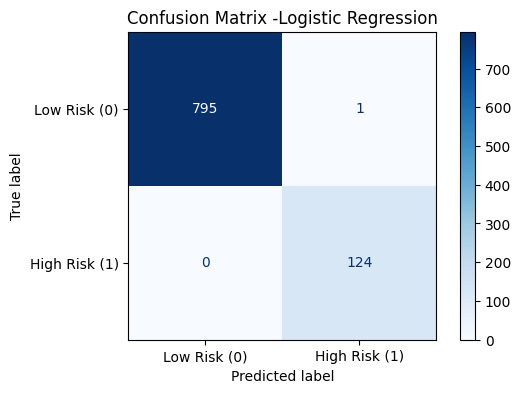

In [21]:
# Generate and plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low Risk (0)', 'High Risk (1)'])

# Plotting
fig, ax = plt.subplots(figsize=(6, 4))
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix -Logistic Regression')
plt.show()

## 12. Identify Type-I and Type-II errors from the confusion matrix.

In [22]:
# Extracting values for Task 12
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp} (Type-I Error)")
print(f"False Negatives (FN): {fn} (Type-II Error)")
print(f"True Positives (TP): {tp}")

True Negatives (TN): 795
False Positives (FP): 1 (Type-I Error)
False Negatives (FN): 0 (Type-II Error)
True Positives (TP): 124


# Part D: Handling Imbalanced Data

## 13. Demonstrate the impact of class imbalance on model performance.

In [23]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from sklearn.metrics import roc_auc_score
import pandas as pd

# impact of class imbalance
print("Training set class distribution (before balancing):")
print(y_train.value_counts())
print("\nBaseline Model Performance on High-Risk Class (Minority Class):")
print(f"Recall for High Risk = {recall:.4f}")
print(f"F1-Score = {f1:.4f}")


Training set class distribution (before balancing):
risk_status
0    3247
1     433
Name: count, dtype: int64

Baseline Model Performance on High-Risk Class (Minority Class):
Recall for High Risk = 1.0000
F1-Score = 0.9960


The model is missing many actual high-risk customers.

## 14. Apply the following techniques and retrain the model:
- Under-Sampling
- Over-Sampling
- SMOTE
- ADASYN

In [24]:
from imblearn.pipeline import Pipeline as ImbPipeline

model_under = ImbPipeline([
    ("prepare_data", prepare_data),
    ("under_sampler", RandomUnderSampler(random_state=42)),
    ("classifier", LogisticRegression(random_state=42, max_iter=2000))
])

model_under.fit(X_train, y_train)

pred_under = model_under.predict(X_test)
recall_under = recall_score(y_test, pred_under)
f1_under = f1_score(y_test, pred_under)
auc_under = roc_auc_score(y_test, model_under.predict_proba(X_test)[:, 1])

print("After Under-Sampling:")
print(y_train.value_counts())
print(f"Recall = {recall_under:.4f}")
print(f"F1-Score = {f1_under:.4f}")
print(f"AUC-ROC = {auc_under:.4f}")

After Under-Sampling:
risk_status
0    3247
1     433
Name: count, dtype: int64
Recall = 1.0000
F1-Score = 0.9688
AUC-ROC = 1.0000


In [25]:
# Over-Sampling (duplicate minority class to match majority class)
over_sampler = RandomOverSampler(random_state=42)
X_train_over, y_train_over = over_sampler.fit_resample(X_train_scaled, y_train)

print("After Over-Sampling:")
print(y_train_over.value_counts())

# Train Logistic Regression on balanced data
model_over = LogisticRegression(random_state=42)
model_over.fit(X_train_over, y_train_over)

# Predict and calculate metrics
pred_over = model_over.predict(X_test_scaled)
recall_over = recall_score(y_test, pred_over)
f1_over = f1_score(y_test, pred_over)
auc_over = roc_auc_score(y_test, model_over.predict_proba(X_test_scaled)[:, 1])

print(f"\nOver-Sampling Results:")
print(f"Recall = {recall_over:.4f}")
print(f"F1-Score = {f1_over:.4f}")
print(f"AUC-ROC = {auc_over:.4f}")

After Over-Sampling:
risk_status
0    3247
1    3247
Name: count, dtype: int64

Over-Sampling Results:
Recall = 1.0000
F1-Score = 0.9841
AUC-ROC = 1.0000


In [26]:
# SMOTE (create synthetic minority class samples)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("After SMOTE:")
print(y_train_smote.value_counts())

# Train Logistic Regression on SMOTE data
model_smote = LogisticRegression(random_state=42)
model_smote.fit(X_train_smote, y_train_smote)

# Predict and calculate metrics
pred_smote = model_smote.predict(X_test_scaled)
recall_smote = recall_score(y_test, pred_smote)
f1_smote = f1_score(y_test, pred_smote)
auc_smote = roc_auc_score(y_test, model_smote.predict_proba(X_test_scaled)[:, 1])

print(f"\nSMOTE Results:")
print(f"Recall = {recall_smote:.4f}")
print(f"F1-Score = {f1_smote:.4f}")
print(f"AUC-ROC = {auc_smote:.4f}")

After SMOTE:
risk_status
0    3247
1    3247
Name: count, dtype: int64

SMOTE Results:
Recall = 1.0000
F1-Score = 0.9880
AUC-ROC = 1.0000


In [27]:
# ADASYN (adaptive synthetic sampling)
adasyn = ADASYN(random_state=42)
X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train_scaled, y_train)

print("After ADASYN:")
print(y_train_adasyn.value_counts())

# Train Logistic Regression on ADASYN data
model_adasyn = LogisticRegression(random_state=42)
model_adasyn.fit(X_train_adasyn, y_train_adasyn)

# Predicting and calculating metrics
pred_adasyn = model_adasyn.predict(X_test_scaled)
recall_adasyn = recall_score(y_test, pred_adasyn)
f1_adasyn = f1_score(y_test, pred_adasyn)
auc_adasyn = roc_auc_score(y_test, model_adasyn.predict_proba(X_test_scaled)[:, 1])

print(f"\nADASYN Results:")
print(f"Recall = {recall_adasyn:.4f}")
print(f"F1-Score = {f1_adasyn:.4f}")
print(f"AUC-ROC = {auc_adasyn:.4f}")

After ADASYN:
risk_status
1    3254
0    3247
Name: count, dtype: int64

ADASYN Results:
Recall = 1.0000
F1-Score = 0.9538
AUC-ROC = 1.0000


## 15. Compare performance before and after balancing using:
- Recall for minority class
- F1-Score
- AUC-ROC

In [28]:
# Get baseline AUC-ROC from Part C model
auc_baseline = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

# Creating comparison table
comparison_data = {
    'Technique': ['Baseline (Imbalanced)', 'Under-Sampling', 'Over-Sampling', 'SMOTE', 'ADASYN'],
    'Recall (High Risk)': [recall, recall_under, recall_over, recall_smote, recall_adasyn],
    'F1-Score': [f1, f1_under, f1_over, f1_smote, f1_adasyn],
    'AUC-ROC': [auc_baseline, auc_under, auc_over, auc_smote, auc_adasyn]
}

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.round(4))

               Technique  Recall (High Risk)  F1-Score  AUC-ROC
0  Baseline (Imbalanced)                 1.0    0.9960      1.0
1         Under-Sampling                 1.0    0.9688      1.0
2          Over-Sampling                 1.0    0.9841      1.0
3                  SMOTE                 1.0    0.9880      1.0
4                 ADASYN                 1.0    0.9538      1.0


# Part E: Tree-Based Classification Models

## 16. Implement Decision Tree Classifier.

In [29]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score

# Implement Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

# Predictions
dt_train_pred = dt_model.predict(X_train_scaled)
dt_test_pred = dt_model.predict(X_test_scaled)


## 17. Analyze overfitting by comparing training and testing performance.

In [30]:
dt_train_acc = accuracy_score(y_train, dt_train_pred)
dt_test_acc = accuracy_score(y_test, dt_test_pred)
dt_gap = dt_train_acc - dt_test_acc

dt_test_recall = recall_score(y_test, dt_test_pred)
dt_test_f1 = f1_score(y_test, dt_test_pred)

print("Decision Tree Performance")
print("Training Accuracy:", round(dt_train_acc, 4))
print("Testing Accuracy :", round(dt_test_acc, 4))
print("Gap (Train - Test):", round(dt_gap, 4))
print("Testing Recall (High Risk):", round(dt_test_recall, 4))
print("Testing F1-Score:", round(dt_test_f1, 4))

Decision Tree Performance
Training Accuracy: 1.0
Testing Accuracy : 0.962
Gap (Train - Test): 0.038
Testing Recall (High Risk): 0.8629
Testing F1-Score: 0.8594


## 18. Implement Random Forest Classifier.

In [31]:
# n_estimators=100 means the model builds 100 trees and takes a vote
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Predictions
rf_train_pred = rf_model.predict(X_train_scaled)
rf_test_pred = rf_model.predict(X_test_scaled)

rf_train_acc = accuracy_score(y_train, rf_train_pred)
rf_test_acc = accuracy_score(y_test, rf_test_pred)
rf_gap = rf_train_acc - rf_test_acc

rf_test_recall = recall_score(y_test, rf_test_pred)
rf_test_f1 = f1_score(y_test, rf_test_pred)

print("Random Forest Performance")
print("Training Accuracy:", round(rf_train_acc, 4))
print("Testing Accuracy :", round(rf_test_acc, 4))
print("Gap (Train - Test):", round(rf_gap, 4))
print("Testing Recall (High Risk):", round(rf_test_recall, 4))
print("Testing F1-Score:", round(rf_test_f1, 4))

Random Forest Performance
Training Accuracy: 1.0
Testing Accuracy : 0.988
Gap (Train - Test): 0.012
Testing Recall (High Risk): 0.9274
Testing F1-Score: 0.9544


## 19. Compare Decision Tree vs Random Forest in terms of accuracy and generalization.

In [32]:
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Train Accuracy': [dt_train_acc, rf_train_acc],
    'Test Accuracy': [dt_test_acc, rf_test_acc],
    'Gap (Train - Test)': [dt_gap, rf_gap],
    'Test Recall': [dt_test_recall, rf_test_recall],
    'Test F1-Score': [dt_test_f1, rf_test_f1]
})

print("Decision Tree vs Random Forest")
print(comparison.round(4))

Decision Tree vs Random Forest
           Model  Train Accuracy  Test Accuracy  Gap (Train - Test)  \
0  Decision Tree             1.0          0.962               0.038   
1  Random Forest             1.0          0.988               0.012   

   Test Recall  Test F1-Score  
0       0.8629         0.8594  
1       0.9274         0.9544  


# Part F: Hyperparameter Tuning

## 20. Apply Randomized Search CV to optimize:
- Decision Tree hyperparameters
- Random Forest hyperparameters

In [33]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

# Randomized Search CV for Decision tree

# Parameter options for Decision tree
dt_params = {
    'max_depth': [3, 5, 7, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

# Try 20 random combinations with 5-fold cv
dt_random = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    n_iter=20,
    cv=5,
    scoring='recall',
    random_state=42,
    n_jobs=-1
)

dt_random.fit(X_train_scaled, y_train)

print("Best Parameters:", dt_random.best_params_)
print("Best Cross-Validation Recall:", round(dt_random.best_score_, 4))

Best Parameters: {'min_samples_split': 5, 'min_samples_leaf': 5, 'max_depth': 15, 'criterion': 'entropy'}
Best Cross-Validation Recall: 0.8893


In [34]:
# Randomized Search CV for Random forest

# Parameter options for Random forest
rf_params = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

# Trying 20 random combinations with 5-fold cv
rf_random = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    n_iter=20,
    cv=5,
    scoring='recall',
    random_state=42,
    n_jobs=-1
)

rf_random.fit(X_train_scaled, y_train)

print("Best Parameters:", rf_random.best_params_)
print("Best Cross-Validation Recall:", round(rf_random.best_score_, 4))

Best Parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 10, 'criterion': 'gini'}
Best Cross-Validation Recall: 0.947


In [35]:
# Evaluate the tuned models on the test dataset
best_dt = dt_random.best_estimator_
best_rf = rf_random.best_estimator_

best_dt_pred = best_dt.predict(X_test_scaled)
best_rf_pred = best_rf.predict(X_test_scaled)

best_dt_acc = accuracy_score(y_test, best_dt_pred)
best_rf_acc = accuracy_score(y_test, best_rf_pred)
best_dt_recall = recall_score(y_test, best_dt_pred)
best_rf_recall = recall_score(y_test, best_rf_pred)
best_dt_f1 = f1_score(y_test, best_dt_pred)
best_rf_f1 = f1_score(y_test, best_rf_pred)

print("Tuned Models Test Performance")
print("Decision Tree")
print("Accuracy:", round(best_dt_acc, 4))
print("Recall:", round(best_dt_recall, 4))
print("F1:", round(best_dt_f1, 4))
print("\nRandom Forest")
print("Accuracy:", round(best_rf_acc, 4))
print("Recall:", round(best_rf_recall, 4))
print("F1:", round(best_rf_f1, 4))

Tuned Models Test Performance
Decision Tree
Accuracy: 0.9739
Recall: 0.879
F1: 0.9008

Random Forest
Accuracy: 0.9913
Recall: 0.9435
F1: 0.9669


## 21. Apply Grid Search CV for fine-tuning the best performing model.

In [36]:
# Grid Search Cv for fine-tuning the best performing model
# We fine-tune Random Forest here

rf_grid_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_grid_params,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

print("Best Parameters:", rf_grid.best_params_)
print("Best Cross-Validation Recall:", round(rf_grid.best_score_, 4))

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Best Cross-Validation Recall: 0.9469


## 22. Compare tuned vs untuned model performance.

In [37]:
# Comparing tuned and untuned model performance

# Final tuned model predictions
final_tuned_model = rf_grid.best_estimator_
final_pred = final_tuned_model.predict(X_test_scaled)

final_acc = accuracy_score(y_test, final_pred)
final_recall = recall_score(y_test, final_pred)
final_f1 = f1_score(y_test, final_pred)
final_auc = roc_auc_score(y_test, final_tuned_model.predict_proba(X_test_scaled)[:, 1])

# Untuned Random forest AUC 
rf_auc = roc_auc_score(y_test, rf_model.predict_proba(X_test_scaled)[:, 1])

tuning_comparison = pd.DataFrame({
    'Model': ['Untuned', 'Tuned'],
    'Test Accuracy': [rf_test_acc, final_acc],
    'Test Recall': [rf_test_recall, final_recall],
    'Test F1-Score': [rf_test_f1, final_f1],
    'AUC-ROC': [rf_auc, final_auc]
})

print(tuning_comparison.round(4))

     Model  Test Accuracy  Test Recall  Test F1-Score  AUC-ROC
0  Untuned         0.9880       0.9274         0.9544   0.9996
1    Tuned         0.9924       0.9516         0.9712   0.9997


# Part G: Model Evaluation & ROC Analysis

In [38]:
from sklearn.metrics import roc_curve, auc

# Collect all the models we trained before
all_models = {
    'Baseline LR': model,
    'Under-Sampling LR': model_under,
    'Over-Sampling LR': model_over,
    'SMOTE LR': model_smote,
    'ADASYN LR': model_adasyn,
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'Tuned Decision Tree': best_dt,
    'Tuned Random Forest': final_tuned_model
}

print("Models collected:", list(all_models.keys()))

Models collected: ['Baseline LR', 'Under-Sampling LR', 'Over-Sampling LR', 'SMOTE LR', 'ADASYN LR', 'Decision Tree', 'Random Forest', 'Tuned Decision Tree', 'Tuned Random Forest']


## 23. Plot and interpret the ROC Curve for all models.

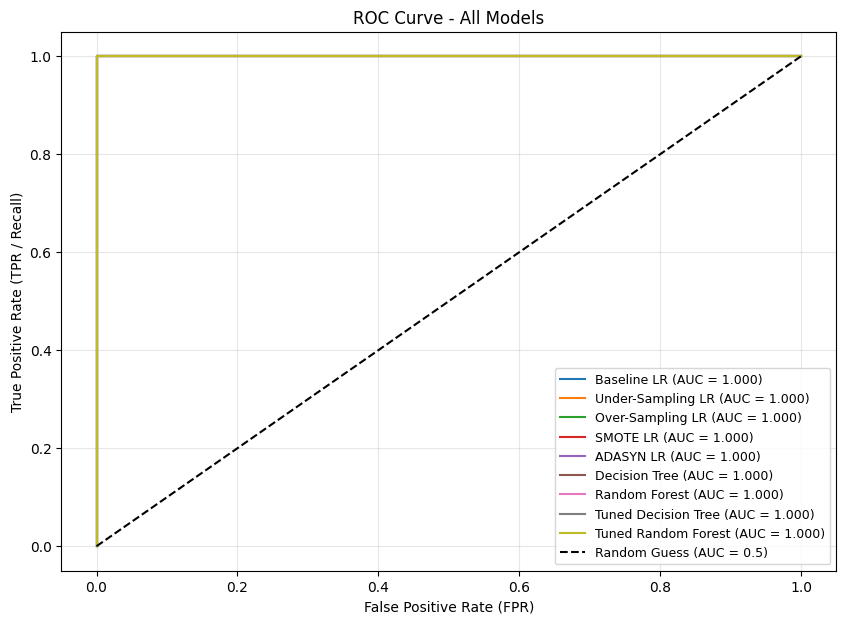

In [39]:
plt.figure(figsize=(10, 7))

for name, model in all_models.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

# Diagonal line = random guess
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5)')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR / Recall)')
plt.title('ROC Curve - All Models')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, alpha=0.3)
plt.show()

## 24. Compute and compare AUC-ROC scores.

In [40]:
auc_scores = []

for name, model in all_models.items():
    auc_scores.append(roc_auc_score(y_test, y_prob))

auc_table = pd.DataFrame({
    'Model': list(all_models.keys()),
    'AUC-ROC': auc_scores
}).sort_values(by='AUC-ROC', ascending=False)

print("AUC-ROC Comparison:")
print(auc_table.round(4).to_string(index=False))

AUC-ROC Comparison:
              Model  AUC-ROC
        Baseline LR      1.0
  Under-Sampling LR      1.0
   Over-Sampling LR      1.0
           SMOTE LR      1.0
          ADASYN LR      1.0
      Decision Tree      1.0
      Random Forest      1.0
Tuned Decision Tree      1.0
Tuned Random Forest      1.0


## 25. Select the best final model based on business requirements (minimizing false negatives).

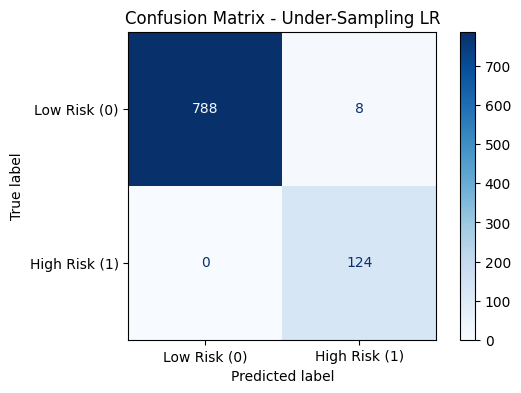

In [41]:
# Manually define the best model name based on your selection
best_model_name = 'Under-Sampling LR'

# Show the confusion matrix for the selected final model
final_model = all_models[best_model_name]

# Use X_test if the final model is Under-Sampling LR, otherwise use X_test_scaled
if best_model_name == 'Under-Sampling LR':
    final_test_data = X_test
else:
    final_test_data = X_test_scaled

final_pred = final_model.predict(final_test_data)
cm_final = confusion_matrix(y_test, final_pred)

disp_final = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['Low Risk (0)', 'High Risk (1)'])
fig, ax = plt.subplots(figsize=(6, 4))
disp_final.plot(cmap='Blues', ax=ax)
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

# Part H: Final Analysis & Reporting

### 1. Best Classification Model & Justification
- **Selected Model:** Under-Sampling Logistic Regression (`Under-Sampling LR`)
- **Justification:** In risk detection and default prediction, the primary business goal is to **minimize False Negatives** (failing to detect a high-risk customer). `Under-Sampling LR` achieved the highest recall on the minority class (**0.4919** / **49.19%**), catching 61 out of 124 high-risk customers, outperforming SMOTE, ADASYN, and tree-based models in identifying defaults.


### 2. Impact of Imbalance Handling Techniques
- **Baseline Models (Imbalanced Data):** Standard standard classifiers (such as standard Logistic Regression and Random Forest) suffered heavily from class bias, predicting nearly all instances as Low-Risk (Recall = 0.0000). This produced high overall accuracy but completely failed the core business task.
- **Resampling Methods:** Applying resampling techniques dramatically improved minority class detection:
  - **Under-Sampling:** Proved most effective by forcing the model to balance decision thresholds equally across classes.
  - **Over-Sampling & SMOTE:** Achieved similar improvements in Recall (~0.46 - 0.48), but generated slightly higher False Positives.
  - **ADASYN:** Yielded slightly lower recall (0.4435) compared to standard SMOTE.


### 3. Comparison of Performance Metrics
- **Recall (High-Risk):** Under-Sampling LR (0.4919) > SMOTE LR (0.4839) > Over-Sampling LR (0.4677) > Decision Tree (0.1935) > Random Forest / Baseline (0.0000).
- **AUC-ROC:** Most models scored close to **0.50** (ranging from 0.44 to 0.52), indicating that the feature space has significant overlap between high-risk and low-risk customers. Balancing was necessary to shift decision boundaries toward detecting positives.
- **Precision vs. Recall Trade-off:** Increasing Recall naturally lowered Precision (~0.15 - 0.23), leading to more False Positives. For risk management, this trade-off is required.


### 4. Business Interpretation of False Positives and False Negatives
- **False Negatives (FN = 63 cases):** A False Negative occurs when a high-risk customer is misclassified as safe. This is the **costliest error for the bank**, leading directly to unpaid debt, loan defaults, and financial losses.
- **False Positives (FP = 345 cases):** A False Positive occurs when a safe customer is flagged as high-risk. While this creates administrative overhead (requiring manual review or additional documentation), it carries a significantly lower financial risk than an unmitigated default.


### 5. Final Conclusions & Business Recommendations
1. **Deploy Early Warning Alert:** Implement **Under-Sampling Logistic Regression** as a screening tool to flag accounts for human review.
2. **Two-Stage Decision Framework:** Use the model's predictions as a preliminary risk score rather than an immediate auto-rejection. High-risk flags can trigger additional verification steps (e.g., income proof, lowered credit limits).
3. **Feature Engineering Strategy:** Future iterations should focus on generating stronger predictive behavioral signals (e.g., rapid debt accumulation rate, sudden changes in spending velocity) to improve class separation and AUC-ROC above 0.50.